# Comparative Intelligence and Ethics in Machine Learning Systems
## MovieLens 100K: Biased Matrix Factorisation and Neural Collaborative Filtering
**ML_PCOM7E July 2026 · Unit 11**

Run all cells in order. Both models use identical splits and ranking candidates. This notebook writes results, charts, model files and a demonstration to `outputs/`. Research benchmark only; no endorsement or production readiness is implied.


## 1. Dataset selection and responsible use

MovieLens 100K is selected because it is a reputable, widely studied GroupLens benchmark containing **100,000 explicit ratings from 943 users on 1,682 films**. It supports both rating prediction and ranking, is small enough for transparent experimentation, and includes limited demographic attributes that permit a cautious fairness audit.

The data are historical (collected in the 1990s), so they do not represent current audiences or catalogues. User IDs are pseudonymous, but age, gender, occupation, and postcode can still create re-identification risk when combined. Demographics are therefore used **only for aggregate diagnostics**, not as predictive inputs. The README/licence must be reviewed before reuse.

Source: GroupLens Research, *MovieLens 100K Dataset*, https://grouplens.org/datasets/movielens/100k/.

The official licence restricts redistribution and requires permission for commercial use. The archive is downloaded from GroupLens rather than supplied with this notebook. Source: https://files.grouplens.org/datasets/movielens/ml-100k-README.txt (Accessed: 19 October 2026).


In [1]:
# Imports and reproducibility
from pathlib import Path
from urllib.request import urlretrieve
import zipfile, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
print('NumPy:', np.__version__, '| pandas:', pd.__version__)

import os, json, hashlib, platform, sys, importlib.metadata
from IPython.display import display
OUT=Path('outputs'); OUT.mkdir(exist_ok=True)
# Keep CPU scheduling comparable on small mini-batches.
os.environ.setdefault('OMP_NUM_THREADS','2')
_fig_no=0
_original_show=plt.show
def save_and_show(*args, **kwargs):
    global _fig_no
    _fig_no += 1
    plt.gcf().savefig(OUT/f'figure_{_fig_no:02d}.png',dpi=160,bbox_inches='tight')
    _original_show(*args, **kwargs)
    plt.close('all')
plt.show=save_and_show


NumPy: 2.3.5 | pandas: 2.2.3


In [2]:
# Download from the official GroupLens host (or reuse an existing local copy)
DATA_DIR = Path('data')
ROOT = DATA_DIR / 'ml-100k'
ZIP_PATH = DATA_DIR / 'ml-100k.zip'
URL = 'https://files.grouplens.org/datasets/movielens/ml-100k.zip'

if not (ROOT / 'u.data').exists():
    DATA_DIR.mkdir(exist_ok=True)
    if not ZIP_PATH.exists():
        print('Downloading MovieLens 100K...')
        urlretrieve(URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)

assert (ROOT / 'u.data').exists(), 'Dataset not found. Place ml-100k inside ./data.'
print('Dataset ready at:', ROOT.resolve())

DATA_SHA256=hashlib.sha256((ROOT/'u.data').read_bytes()).hexdigest()
print('Rating-file SHA-256:',DATA_SHA256)


Dataset ready at: /workspace/scratch/46e03c412083/output/data/ml-100k
Rating-file SHA-256: 06416e597f82b7342361e41163890c81036900f418ad91315590814211dca490


In [3]:
# Load ratings, users and items
ratings = pd.read_csv(ROOT/'u.data', sep='\t', names=['user_id','item_id','rating','timestamp'])
users = pd.read_csv(ROOT/'u.user', sep='|', names=['user_id','age','gender','occupation','zip_code'])
item_cols = ['item_id','title','release_date','video_release_date','IMDb_URL'] + [
    'unknown','Action','Adventure','Animation','Children','Comedy','Crime','Documentary','Drama',
    'Fantasy','Film-Noir','Horror','Musical','Mystery','Romance','Sci-Fi','Thriller','War','Western']
items = pd.read_csv(ROOT/'u.item', sep='|', names=item_cols, encoding='latin-1')

print('Ratings shape:', ratings.shape, '| users:', users.shape[0], '| items:', items.shape[0])
display(ratings.head())
display(ratings['rating'].describe().to_frame().T)
print('Missing values in core rating fields:', ratings[['user_id','item_id','rating']].isna().sum().to_dict())
print('Duplicate user-item pairs:', ratings.duplicated(['user_id','item_id']).sum())


Ratings shape: (100000, 4) | users: 943 | items: 1682
Missing values in core rating fields: {'user_id': 0, 'item_id': 0, 'rating': 0}
Duplicate user-item pairs: 0


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,count,mean,std,min,25%,50%,75%,max
rating,100000.0,3.52986,1.125674,1.0,3.0,4.0,4.0,5.0


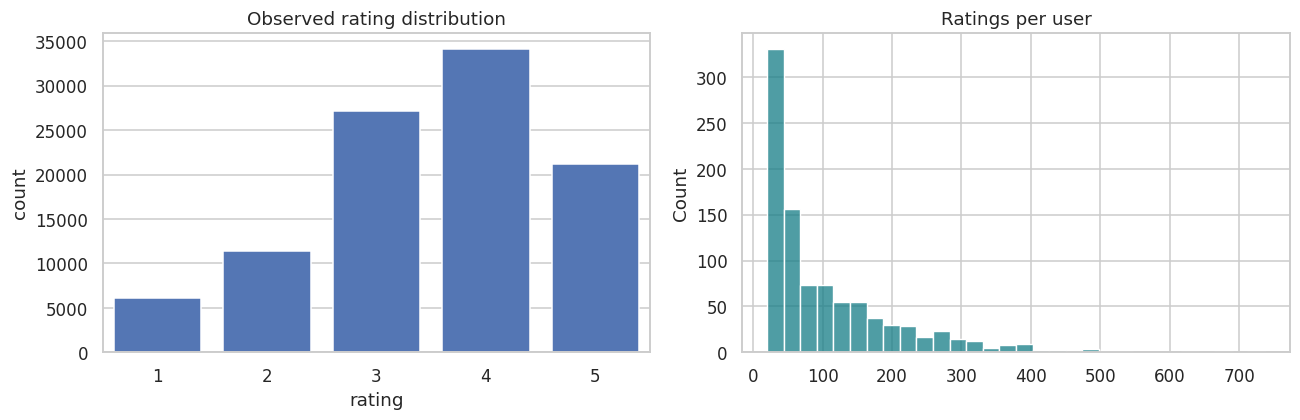

In [4]:
# Descriptive distributions only. Activity groups are defined after splitting.
user_counts=ratings.groupby('user_id').size()
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(data=ratings,x='rating',ax=ax[0],color='#4472C4')
ax[0].set_title('Observed rating distribution')
sns.histplot(user_counts,bins=30,ax=ax[1],color='#147D86')
ax[1].set_title('Ratings per user'); plt.tight_layout(); plt.show()


## 2. Preprocessing and validation design

The primary split takes each user's latest rating for test, second latest for validation, and earlier ratings for training. It preserves within-user chronology but does **not** enforce a global time cutoff across users. Tied timestamps are resolved deterministically by item ID; this does not recover their real event order. A three-fold development sensitivity check uses separate inner early-stopping data. It measures partition sensitivity, not prospective deployment performance. A production assessment should additionally use global chronological windows.

All feature-derived activity groups use training data only. Demographics remain outside the model inputs. Known-identity benchmark coverage is reported explicitly; untrained identities receive a documented fallback.


In [5]:
# Encode IDs and create temporal train/validation/test sets
u_values = np.sort(ratings.user_id.unique())
i_values = np.sort(ratings.item_id.unique())
u_map = {v:k for k,v in enumerate(u_values)}
i_map = {v:k for k,v in enumerate(i_values)}
ratings['u'] = ratings.user_id.map(u_map).astype(int)
ratings['i'] = ratings.item_id.map(i_map).astype(int)

ordered = ratings.sort_values(['user_id','timestamp','item_id'],kind='stable')
test_idx = ordered.groupby('user_id').tail(1).index
remaining = ordered.drop(test_idx)
val_idx = remaining.groupby('user_id').tail(1).index
train_idx = remaining.drop(val_idx).index
train, val, test = (ratings.loc[x].copy() for x in [train_idx, val_idx, test_idx])

n_users, n_items = len(u_values), len(i_values)
global_mean = train.rating.mean()
print({'train':len(train), 'validation':len(val), 'test':len(test),
       'users':n_users, 'items':n_items, 'train_mean':round(global_mean,3)})
assert set(train.index).isdisjoint(val.index) and set(train.index).isdisjoint(test.index)

assert set(val.index).isdisjoint(test.index)
assert len(train)+len(val)+len(test)==len(ratings)
assert (ratings.rating.between(1,5)).all()
training_counts=train.groupby('user_id').size()
# Quantiles across users, not repeated rating rows.
activity_bins=pd.qcut(training_counts.rank(method='first'),q=3,labels=['low','medium','high'])
test['activity_group']=test.user_id.map(activity_bins)
train[['user_id','item_id','timestamp']].to_csv(OUT/'train_split.csv',index=False)
val[['user_id','item_id','timestamp']].to_csv(OUT/'validation_split.csv',index=False)
test[['user_id','item_id','timestamp']].to_csv(OUT/'test_split.csv',index=False)


{'train': 98114, 'validation': 943, 'test': 943, 'users': 943, 'items': 1682, 'train_mean': np.float64(3.532)}


## 3. Model 1 — classical biased matrix factorisation

The model estimates $\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i$. The global mean and user/item biases capture systematic rating tendencies; latent vectors capture interaction patterns. We use 20 latent factors, L2 regularisation, shuffled stochastic gradient descent, and early stopping. These choices balance capacity, overfitting risk and laptop runtime.


In [6]:
class BiasedMF:
    def __init__(self, n_users, n_items, factors=20, lr=.01, reg=.03, epochs=25, patience=3, seed=42):
        self.n_users, self.n_items = n_users, n_items
        self.factors, self.lr, self.reg = factors, lr, reg
        self.epochs, self.patience, self.seed = epochs, patience, seed

    def fit(self, frame, valid=None, verbose=True):
        rng = np.random.default_rng(self.seed)
        self.mu = frame.rating.mean()
        self.seen_u=np.zeros(self.n_users,dtype=bool); self.seen_i=np.zeros(self.n_items,dtype=bool)
        self.seen_u[frame.u.unique()]=True; self.seen_i[frame.i.unique()]=True
        self.P = rng.normal(0, .1, (self.n_users, self.factors))
        self.Q = rng.normal(0, .1, (self.n_items, self.factors))
        self.bu = np.zeros(self.n_users); self.bi = np.zeros(self.n_items)
        rows = frame[['u','i','rating']].to_numpy()
        best, wait, self.history = np.inf, 0, []
        for epoch in range(self.epochs):
            rng.shuffle(rows)
            for u, i, r in rows:
                u, i = int(u), int(i)
                pu = self.P[u].copy(); qi = self.Q[i].copy()
                err = r - (self.mu + self.bu[u] + self.bi[i] + pu @ qi)
                self.bu[u] += self.lr * (err - self.reg*self.bu[u])
                self.bi[i] += self.lr * (err - self.reg*self.bi[i])
                self.P[u] += self.lr * (err*qi - self.reg*pu)
                self.Q[i] += self.lr * (err*pu - self.reg*qi)
            target = valid if valid is not None else frame
            score = rmse(target.rating, self.predict(target.u, target.i))
            self.history.append(score)
            if score < best - 1e-4:
                best, wait = score, 0
                state = [x.copy() if hasattr(x,'copy') else x for x in (self.P,self.Q,self.bu,self.bi)]
            else:
                wait += 1
                if wait >= self.patience: break
        self.P,self.Q,self.bu,self.bi = state
        if verbose: print(f'MF epochs={len(self.history)}, best validation RMSE={best:.4f}')
        return self

    def predict(self, users, items):
        u = np.asarray(users, dtype=int); i = np.asarray(items, dtype=int)
        out = self.mu + self.bu[u] + self.bi[i] + np.sum(self.P[u]*self.Q[i], axis=1)
        known=self.seen_u[u]&self.seen_i[i]
        fallback=self.mu+self.bu[u]*self.seen_u[u]+self.bi[i]*self.seen_i[i]
        return np.clip(np.where(known,out,fallback),1,5)

def rmse(y, pred): return mean_squared_error(y, pred) ** .5

started=time.perf_counter()
mf = BiasedMF(n_users, n_items).fit(train, val)
mf_seconds=time.perf_counter()-started


MF epochs=18, best validation RMSE=1.0062


## 4. Model 2 — deep neural collaborative filtering

NCF learns separate user and movie embeddings, concatenates them, and passes them through two dense ReLU layers (64 and 32 units) to predict a rating. A sigmoid output is rescaled to 1–5. Mini-batch Adam, L2 weight decay, early stopping, and a learning-rate schedule provide a stable training strategy.

PyTorch is used because its modules make the architecture auditable and its automatic differentiation reduces implementation error. If PyTorch is absent, uncomment the installation line.


In [7]:
# If needed in a fresh notebook environment, uncomment:
# %pip install -q torch
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
except ImportError as e:
    raise ImportError('PyTorch is required. Run `%pip install torch` and restart the kernel.') from e

torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

class NCF(nn.Module):
    def __init__(self, n_users, n_items, emb=24):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, emb)
        self.item_emb = nn.Embedding(n_items, emb)
        self.net = nn.Sequential(nn.Linear(2*emb,64), nn.ReLU(), nn.Dropout(.15),
                                 nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1))
    def forward(self, u, i):
        z = torch.cat([self.user_emb(u), self.item_emb(i)], dim=1)
        return 1 + 4*torch.sigmoid(self.net(z).squeeze(1))

def loader(frame, batch=1024, shuffle=False):
    ds = TensorDataset(torch.tensor(frame.u.values, dtype=torch.long),
                       torch.tensor(frame.i.values, dtype=torch.long),
                       torch.tensor(frame.rating.values, dtype=torch.float32))
    return DataLoader(ds, batch_size=batch, shuffle=shuffle)

@torch.no_grad()
def ncf_predict(model, frame):
    model.eval(); out=[]
    for u,i,_ in loader(frame, 4096):
        out.append(model(u.to(device),i.to(device)).cpu().numpy())
    pred=np.concatenate(out)
    if hasattr(model,'seen_u'):
        known=model.seen_u[frame.u.to_numpy()] & model.seen_i[frame.i.to_numpy()]
        pred=np.where(known,pred,model.fallback_mean)
    return pred

def fit_ncf(train_df, valid_df, epochs=20, patience=3, verbose=True):
    torch.manual_seed(SEED)
    model = NCF(n_users,n_items).to(device)
    model.seen_u=np.zeros(n_users,dtype=bool); model.seen_i=np.zeros(n_items,dtype=bool)
    model.seen_u[train_df.u.unique()]=True; model.seen_i[train_df.i.unique()]=True
    model.fallback_mean=float(train_df.rating.mean())
    opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=.5, patience=1)
    loss_fn = nn.MSELoss(); best=np.inf; wait=0; history=[]
    for ep in range(epochs):
        model.train()
        for u,i,r in loader(train_df,1024,True):
            u,i,r = u.to(device),i.to(device),r.to(device)
            opt.zero_grad(); loss=loss_fn(model(u,i),r); loss.backward(); opt.step()
        score=rmse(valid_df.rating,ncf_predict(model,valid_df)); history.append(score); sched.step(score)
        if score < best-1e-4:
            best,wait,state=score,0,copy.deepcopy(model.state_dict())
        else:
            wait+=1
            if wait>=patience: break
    model.load_state_dict(state)
    if verbose: print(f'NCF epochs={len(history)}, best validation RMSE={best:.4f}')
    return model,history

started=time.perf_counter()
ncf,ncf_history = fit_ncf(train,val)
ncf_seconds=time.perf_counter()-started


Device: cpu
NCF epochs=12, best validation RMSE=1.0187


## 5. Validation and final evaluation

RMSE measures rating-prediction error and penalises large errors. NDCG@10 evaluates whether relevant movies (held-out ratings ≥4) appear near the top of a ranked list. For each eligible user, ranking compares the held-out relevant item with up to 100 reproducibly sampled unrated items. This candidate-sampling protocol must be reported because sampled NDCG is not identical to ranking the full catalogue.

Three-fold cross-validation on development data estimates sensitivity to a particular split. Validation is essential because training performance alone is optimistic and cannot reveal generalisation or overfitting.


In [8]:
def sampled_ndcg_at_k(model_predict_pairs, train_seen, test_df, k=10, negatives=100, seed=42):
    rng=np.random.default_rng(seed); scores=[]; all_items=np.arange(n_items)
    seen_by_user=train_seen.groupby('u').i.apply(set).to_dict()
    for row in test_df.itertuples():
        if row.rating < 4: continue
        unseen=np.setdiff1d(all_items, np.fromiter(seen_by_user.get(row.u,set())|{row.i},dtype=int))
        neg=rng.choice(unseen,size=min(negatives,len(unseen)),replace=False)
        cand=np.r_[row.i,neg]; users=np.repeat(row.u,len(cand))
        pred=model_predict_pairs(users,cand)
        rank=int(np.where(np.argsort(-pred)==0)[0][0])+1
        scores.append(1/np.log2(rank+1) if rank<=k else 0.0)
    return float(np.mean(scores)),len(scores)

mf_test_pred=mf.predict(test.u,test.i)
ncf_test_pred=ncf_predict(ncf,test)
seen=pd.concat([train,val])
mf_ndcg,n_eval=sampled_ndcg_at_k(mf.predict,seen,test)

def ncf_pairs(users,items):
    frame=pd.DataFrame({'u':users,'i':items,'rating':np.zeros(len(users))})
    return ncf_predict(ncf,frame)
ncf_ndcg,_=sampled_ndcg_at_k(ncf_pairs,seen,test)

results=pd.DataFrame({
    'Model':['Biased matrix factorisation','Neural collaborative filtering'],
    'Test RMSE':[rmse(test.rating,mf_test_pred),rmse(test.rating,ncf_test_pred)],
    'Sampled NDCG@10':[mf_ndcg,ncf_ndcg],
    'Parameters':[mf.P.size+mf.Q.size+len(mf.bu)+len(mf.bi),sum(p.numel() for p in ncf.parameters())]
})
display(results.style.format({'Test RMSE':'{:.4f}','Sampled NDCG@10':'{:.4f}','Parameters':'{:,}'}))
print('Eligible held-out relevant ratings used for NDCG:',n_eval)

results['Training seconds']=[mf_seconds,ncf_seconds]
results.to_csv(OUT/'model_comparison.csv',index=False)


Eligible held-out relevant ratings used for NDCG: 459


,Model,Test RMSE,Sampled NDCG@10,Parameters
0,Biased matrix factorisation,1.0438,0.1478,"55,125"
1,Neural collaborative filtering,1.0600,0.1450,"68,249"


,mean,std
model,,
MF,0.9414,0.0021
NCF,0.9578,0.0030


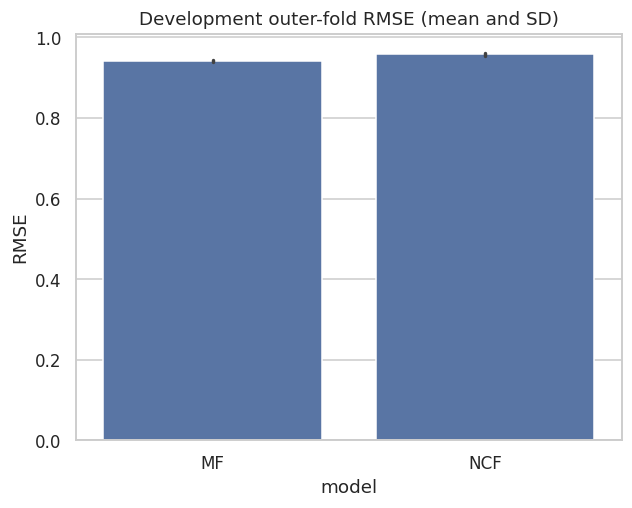

In [9]:
# Outer folds remain independent of early-stopping decisions.
from sklearn.model_selection import train_test_split
development=pd.concat([train,val]).reset_index(drop=True)
kf=KFold(n_splits=3,shuffle=True,random_state=SEED)
cv=[]
for fold,(tr_idx,outer_idx) in enumerate(kf.split(development),1):
    inner_train_idx,inner_val_idx=train_test_split(tr_idx,test_size=.15,random_state=SEED+fold)
    tr,iv,outer=development.iloc[inner_train_idx],development.iloc[inner_val_idx],development.iloc[outer_idx]
    assert set(inner_train_idx).isdisjoint(outer_idx)
    assert set(inner_val_idx).isdisjoint(outer_idx)
    fold_mf=BiasedMF(n_users,n_items,epochs=25,patience=3,seed=SEED+fold).fit(tr,iv,False)
    fold_ncf,_=fit_ncf(tr,iv,epochs=20,patience=3,verbose=False)
    cv += [{'fold':fold,'model':'MF','RMSE':rmse(outer.rating,fold_mf.predict(outer.u,outer.i))},
           {'fold':fold,'model':'NCF','RMSE':rmse(outer.rating,ncf_predict(fold_ncf,outer))}]
cv=pd.DataFrame(cv)
cv_summary=cv.groupby('model').RMSE.agg(['mean','std'])
display(cv_summary.round(4)); cv.to_csv(OUT/'development_folds.csv',index=False)
cv_summary.to_csv(OUT/'development_summary.csv')
sns.barplot(data=cv,x='model',y='RMSE',errorbar='sd')
plt.title('Development outer-fold RMSE (mean and SD)'); plt.show()


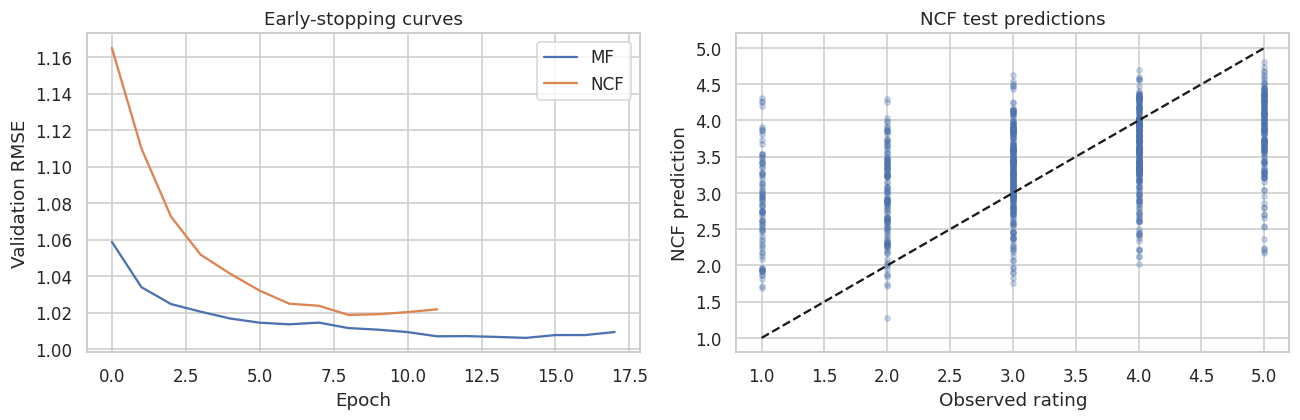

In [10]:
# Training curves and observed-versus-predicted diagnostic
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(mf.history,label='MF'); ax[0].plot(ncf_history,label='NCF')
ax[0].set(xlabel='Epoch',ylabel='Validation RMSE',title='Early-stopping curves'); ax[0].legend()
ax[1].scatter(test.rating,ncf_test_pred,alpha=.25,s=12)
ax[1].plot([1,5],[1,5],'k--'); ax[1].set(xlabel='Observed rating',ylabel='NCF prediction',title='NCF test predictions')
plt.tight_layout(); plt.show()


## 6. Explainability

Two complementary methods are used:

- **MF decomposition:** separates global mean, user bias, item bias and latent interaction for individual predictions.
- **Model-agnostic permutation importance for NCF:** independently shuffles user IDs or movie IDs and measures the increase in test RMSE. A larger increase means predictions depend more strongly on that input identity. This explains global reliance but does not establish causality.


Movie: Aristocats, The (1970) | observed: 2 | predicted: 2.808
Final clipped score: 2.8078425208636757


,contribution
global mean,3.532
user bias,-0.078
item bias,-0.226
latent interaction,-0.421


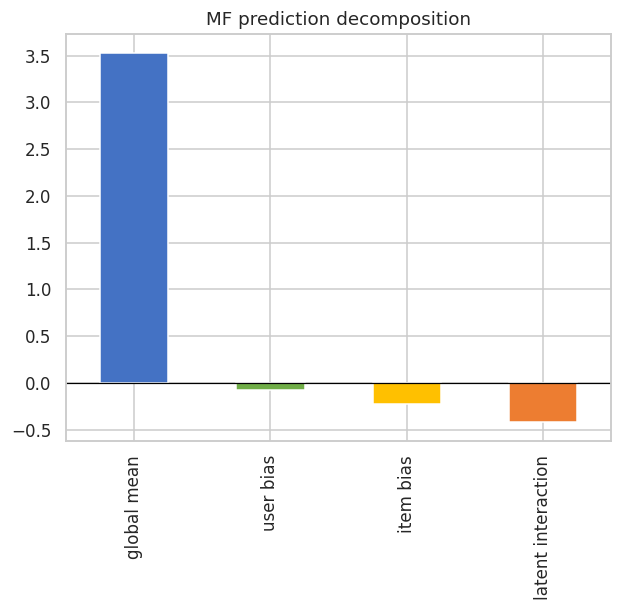

In [11]:
# Local additive explanation for one MF prediction
example=test.iloc[0]; u,i=int(example.u),int(example.i)
parts=pd.Series({'global mean':mf.mu,'user bias':mf.bu[u],'item bias':mf.bi[i],
                 'latent interaction':mf.P[u]@mf.Q[i]})
display(parts.to_frame('contribution').style.format('{:.3f}'))
print('Movie:',items.set_index('item_id').loc[example.item_id,'title'],
      '| observed:',example.rating,'| predicted:',round(float(parts.sum()),3))
parts.plot(kind='bar',color=['#4472C4','#70AD47','#FFC000','#ED7D31'],title='MF prediction decomposition');
plt.axhline(0,color='black',lw=.8); plt.show()

print('Final clipped score:',float(mf.predict([u],[i])[0]))
parts.rename('contribution').to_csv(OUT/'mf_explanation.csv')


mean       std
model input                    
MF    i      0.256980  0.018174
      u      0.139629  0.013757
NCF   i      0.226974  0.015846
      u      0.111175  0.013015

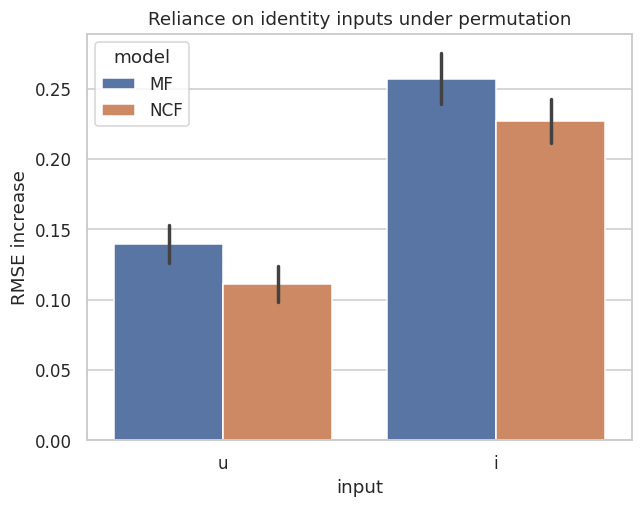

In [12]:
# Repeated permutation reliance diagnostics for both models.
importance=[]
for model_name,predict,original in [
    ('MF',lambda f:mf.predict(f.u,f.i),mf_test_pred),
    ('NCF',lambda f:ncf_predict(ncf,f),ncf_test_pred)]:
    baseline=rmse(test.rating,original)
    for feature in ['u','i']:
        for repeat in range(10):
            rng=np.random.default_rng(SEED+repeat)
            perm=test.copy(); perm[feature]=rng.permutation(perm[feature].values)
            importance.append({'model':model_name,'input':feature,'repeat':repeat,
                               'RMSE increase':rmse(test.rating,predict(perm))-baseline})
importance=pd.DataFrame(importance)
importance.to_csv(OUT/'permutation_repeats.csv',index=False)
importance_summary=importance.groupby(['model','input'])['RMSE increase'].agg(['mean','std'])
display(importance_summary)
importance_summary.to_csv(OUT/'permutation_summary.csv')
sns.barplot(data=importance,x='input',y='RMSE increase',hue='model',errorbar='sd')
plt.title('Reliance on identity inputs under permutation'); plt.show()


## 7. Bias and diagnostic analysis

Performance is compared across user activity, gender, and age bands. This is a **diagnostic**, not proof of fairness: binary gender categories are historically imposed by the dataset, group sizes differ, intersectional groups may be hidden, and equal RMSE does not guarantee equal recommendation quality or exposure. Report both metric and sample size; avoid conclusions for very small groups.



 activity_group

 gender

 age_group


,activity_group,n,MF_RMSE,NCF_RMSE
0,low,314,1.0819,1.0832
1,medium,314,1.0603,1.0759
2,high,315,0.9869,1.0198


,gender,n,MF_RMSE,NCF_RMSE
0,F,273,1.0710,1.0990
1,M,670,1.0325,1.0436


,age_group,n,MF_RMSE,NCF_RMSE
0,<25,234,1.0767,1.0832
1,25–34,310,1.0484,1.0832
2,35–49,274,1.0290,1.0454
3,50+,125,1.0007,0.9869


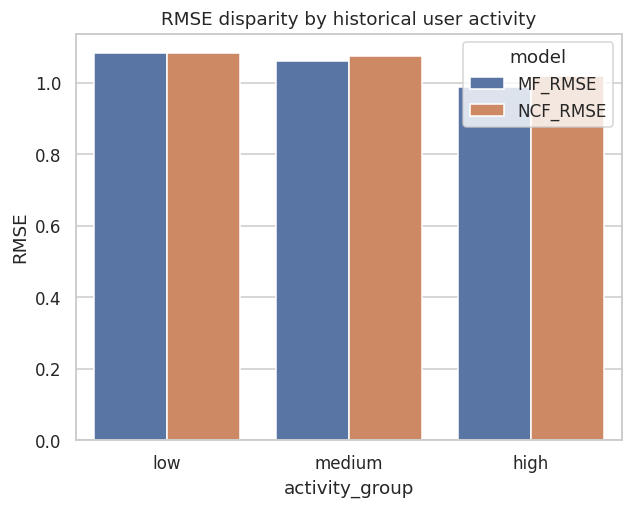

In [13]:
# Merge demographic attributes solely after prediction; they were not model inputs
audit=test[['user_id','activity_group','rating']].copy()
audit['MF_error']=(audit.rating.values-mf_test_pred)**2
audit['NCF_error']=(audit.rating.values-ncf_test_pred)**2
audit=audit.merge(users[['user_id','age','gender']],on='user_id',how='left')
audit['age_group']=pd.cut(audit.age,[0,24,34,49,120],labels=['<25','25–34','35–49','50+'])

def subgroup_table(column):
    return audit.groupby(column,observed=True).agg(
        n=('rating','size'), MF_RMSE=('MF_error',lambda x:np.sqrt(x.mean())),
        NCF_RMSE=('NCF_error',lambda x:np.sqrt(x.mean()))).reset_index()

for col in ['activity_group','gender','age_group']:
    print('\n',col)
    display(subgroup_table(col).round(4))

activity=subgroup_table('activity_group').melt(id_vars=['activity_group','n'],var_name='model',value_name='RMSE')
sns.barplot(data=activity,x='activity_group',y='RMSE',hue='model');
plt.title('RMSE disparity by historical user activity'); plt.show()

for col in ['activity_group','gender','age_group']:
    subgroup_table(col).to_csv(OUT/f'subgroups_{col}.csv',index=False)


In [14]:
# Standard thresholded relevance confusion rates on observed held-out ratings only.
# These cannot measure exposure to unrated films or the entire catalogue.
diagnostic=pd.DataFrame({'actual':test.rating.to_numpy(),'MF':mf_test_pred,'NCF':ncf_test_pred})
error_rates=[]
for name in ['MF','NCF']:
    positive=diagnostic.actual>=4; predicted=diagnostic[name]>=4
    tp=int((positive&predicted).sum()); fp=int((~positive&predicted).sum())
    fn=int((positive&~predicted).sum()); tn=int((~positive&~predicted).sum())
    error_rates.append({'model':name,'TP':tp,'FP':fp,'FN':fn,'TN':tn,
        'false_positive_rate':fp/(fp+tn) if fp+tn else np.nan,
        'false_negative_rate':fn/(fn+tp) if fn+tp else np.nan})
error_rates=pd.DataFrame(error_rates); display(error_rates)
error_rates.to_csv(OUT/'relevance_error_rates.csv',index=False)


,model,TP,FP,FN,TN,false_positive_rate,false_negative_rate
0,MF,145,31,314,453,0.064050,0.684096
1,NCF,143,30,316,454,0.061983,0.688453


## 8. Critical ethical reflection

**Privacy and provenance.** MovieLens is research data released by GroupLens, but pseudonymisation is not anonymisation. Postcodes and demographics can enable linkage attacks. A production system should minimise collection, separate identifiers from events, encrypt data, restrict access, set retention limits, document lawful basis/consent, and support deletion and opt-out.

**Fairness and representational bias.** Heavy users generate more labels, so optimisation may serve them better. Historical popularity can amplify already-visible films, while sparse/new users and new items face cold-start disadvantage. Aggregate RMSE can hide these harms. Production monitoring should stratify ranking quality, coverage, exposure, and error by activity and legitimately collected demographic groups, with minimum sample thresholds and intersectional review.

**Consequences of errors.** A false positive wastes attention and can expose a user to unsuitable content; a false negative suppresses relevant or minority-interest content. In higher-stakes domains, the same architecture should not be transferred without a new harm assessment. Users should be able to dismiss recommendations and understand the main reason for them.

**Limitations.** MovieLens 100K is old, offline feedback is not the same as online satisfaction, missing ratings are not necessarily dislikes, sampled NDCG depends on the candidate protocol, and demographic fields are incomplete social proxies. The audit therefore identifies risks rather than certifying fairness.


## 9. Deployment recommendation and architecture

**Recommended model:** deploy matrix factorisation as the initial baseline if its test RMSE/NDCG are close to NCF. It is smaller, faster, easier to decompose, and more appropriate for this modest dataset. Choose NCF only if the executed results show a meaningful and stable ranking gain that justifies extra latency, monitoring and explanation burden.

**Proposed deployment:** package preprocessing maps and the versioned model together; expose a stateless HTTPS recommendation API; cache popular recommendations; retrieve candidate items before scoring; and log privacy-minimised operational metrics. A cloud platform such as SageMaker, Vertex AI or Azure ML could host the inference container and model registry.

**Monitoring:** track p95 latency, failures, score drift, catalogue coverage, activity-stratified NDCG, exposure concentration, and user feedback. Trigger investigation—not automatic retraining—when thresholds are breached. Retraining should use a versioned snapshot, repeat offline validation/fairness checks, pass human approval, and support rollback. Use a popularity fallback for unseen users and content features or exploration for unseen items.

```text
Client → API gateway → candidate retrieval → model scoring → policy/filter layer → ranked results
                                      ↘ monitoring, drift and fairness dashboard
```


In [15]:
# Compact, automatically generated evidence table for presentation slides
winner_rmse=results.loc[results['Test RMSE'].idxmin(),'Model']
winner_ndcg=results.loc[results['Sampled NDCG@10'].idxmax(),'Model']
summary=pd.DataFrame({
    'Decision evidence':['Lowest test RMSE','Highest sampled NDCG@10','Validation method','XAI method','Key bias slices'],
    'Finding':[winner_rmse,winner_ndcg,'Per-user temporal test + 3-fold development sensitivity',
               'MF decomposition + NCF permutation importance','Activity, gender and age']})
display(summary)


,Decision evidence,Finding
0,Lowest test RMSE,Biased matrix factorisation
1,Highest sampled NDCG@10,Biased matrix factorisation
2,Validation method,Per-user temporal test + 3-fold development se...
3,XAI method,MF decomposition + NCF permutation importance
4,Key bias slices,"Activity, gender and age"


## 10. Conclusion

This comparison avoids treating predictive accuracy as the sole form of intelligence. The final decision should combine test and cross-validation performance, ranking quality, subgroup diagnostics, interpretability, compute cost, privacy risk, and operational monitoring. Record the numerical outputs after executing the notebook and transfer the charts—not dense code—to the presentation.

### References

- Harper, F.M. and Konstan, J.A. (2015) ‘The MovieLens datasets: History and context’, *ACM Transactions on Interactive Intelligent Systems*, 5(4), pp. 1–19. https://doi.org/10.1145/2827872.
- He, X., Liao, L., Zhang, H., Nie, L., Hu, X. and Chua, T.-S. (2017) ‘Neural collaborative filtering’, *Proceedings of the 26th International Conference on World Wide Web*, pp. 173–182. https://doi.org/10.1145/3038912.3052569.
- Koren, Y., Bell, R. and Volinsky, C. (2009) ‘Matrix factorization techniques for recommender systems’, *Computer*, 42(8), pp. 30–37. https://doi.org/10.1109/MC.2009.263.
- Tabassi, E. (2023) *Artificial Intelligence Risk Management Framework (AI RMF 1.0)*. Gaithersburg, MD: National Institute of Standards and Technology. https://doi.org/10.6028/NIST.AI.100-1.
- Rendle, S., Zhang, L. and Koren, Y. (2019) ‘On the difficulty of evaluating baselines: A study on recommender systems’, arXiv:1905.01395. https://doi.org/10.48550/arXiv.1905.01395.

- GroupLens Research (1998) *MovieLens 100K README*. Available at: https://files.grouplens.org/datasets/movielens/ml-100k-README.txt (Accessed: 19 October 2026).
- Rendle, S., Krichene, W., Zhang, L. and Anderson, J. (2020) ‘Neural collaborative filtering vs. matrix factorization revisited’, *Proceedings of RecSys 2020*, pp. 240–248. https://doi.org/10.1145/3383313.3412488.


## 11. Saved demonstration and reproducibility

Use the saved outputs during recording. Compare the observed rating with both predictions, inspect the score decomposition, then display the ranked recommendations. Film scores are model estimates rather than verified user judgements. The software saves weights and maps for local reuse; it does not implement or certify a production deployment.


In [16]:
# Save a reproducible demonstration and trained model artefacts.
demo=test.iloc[0]; demo_user=int(demo.u)
seen_items=set(pd.concat([train,val]).query('u == @demo_user').i)
candidates=np.array([j for j in range(n_items) if j not in seen_items])
demo_frame=pd.DataFrame({'u':demo_user,'i':candidates,'rating':0.0})
demo_frame['MF']=mf.predict(demo_frame.u,demo_frame.i)
demo_frame['NCF']=ncf_predict(ncf,demo_frame)
demo_frame['item_id']=[int(i_values[j]) for j in candidates]
demo_frame=demo_frame.merge(items[['item_id','title']],on='item_id',how='left')
display(demo_frame.nlargest(10,'MF')[['title','MF','NCF']])
demo_frame.nlargest(10,'MF')[['item_id','title','MF','NCF']].to_csv(OUT/'demo_top10_MF.csv',index=False)
demo_frame.nlargest(10,'NCF')[['item_id','title','MF','NCF']].to_csv(OUT/'demo_top10_NCF.csv',index=False)
demo_info={'user_id':int(demo.user_id),'item_id':int(demo.item_id),
           'observed':float(demo.rating),'MF':float(mf.predict([int(demo.u)],[int(demo.i)])[0]),
           'NCF':float(ncf_predict(ncf,test.iloc[[0]])[0])}
(OUT/'demo_prediction.json').write_text(json.dumps(demo_info,indent=2))
np.savez_compressed(OUT/'mf_weights.npz',P=mf.P,Q=mf.Q,bu=mf.bu,bi=mf.bi,
                    mu=mf.mu,seen_u=mf.seen_u,seen_i=mf.seen_i)
torch.save({'state_dict':ncf.state_dict(),'seen_u':ncf.seen_u.tolist(),
            'seen_i':ncf.seen_i.tolist(),'fallback_mean':ncf.fallback_mean,
            'n_users':n_users,'n_items':n_items,'embedding_dim':24},OUT/'ncf_weights.pt')
maps={'user_ids':[int(v) for v in u_values],'item_ids':[int(v) for v in i_values]}
(OUT/'identifier_maps.json').write_text(json.dumps(maps))
versions={name:importlib.metadata.version(name) for name in
          ['numpy','pandas','matplotlib','seaborn','scikit-learn','torch']}
manifest={'python':sys.version,'platform':platform.platform(),'packages':versions,
          'seed':SEED,'data_sha256':DATA_SHA256,'split':'per-user last two events',
          'train':len(train),'validation':len(val),'test':len(test),
          'ranking_candidates':'one positive plus up to 100 unlabelled items',
          'ranking_eligible_users':n_eval,'execution_status':'completed'}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Saved all outputs to',OUT.resolve())


Saved all outputs to /workspace/scratch/46e03c412083/output/outputs


,title,MF,NCF
136,"Close Shave, A (1995)",5.000000,4.627126
30,L.A. Confidential (1997),4.811122,4.371745
13,Secrets & Lies (1996),4.741270,4.466169
385,"Manchurian Candidate, The (1962)",4.724397,4.408260
41,Titanic (1997),4.720046,4.386724
202,Dr. Strangelove or: How I Learned to Stop Worr...,4.646609,4.426062
3,Sense and Sensibility (1995),4.615109,4.195041
369,Paths of Glory (1957),4.588723,4.282415
211,Casablanca (1942),4.577480,4.558641
647,"City of Lost Children, The (1995)",4.540460,4.079958
